# 08 Alerta-sistema adituna

Arauetan oinarritutako sistema aditu bat egingo dugu, airearen kalitateari buruzko alertak ematen dituena ingurumen-datuak eta ereduen irteerak (MLP, zuhaitza eta K-means) konbinatuz.

Sistema aditu batek bere atalak ditu, eta gurean honela daude:

| Atala | Gure sisteman |
|---|---|
| Ezagutza-basea | 5 arauak, haien ziurtasun-faktoreak eta atalaseak (jetson/sistema.py-ko ARAUAK eta ATALASEAK) |
| Egitate-basea | Uneko orduko datuak eta ereduen iragarpenak |
| Inferentzia-motorra | arauak_aplikatu: egitateetatik abiatuta betetzen diren arauak bilatzen ditu (aurrerantzko kateatzea) |
| Azalpen-modulua | Alerta bakoitzak zein arauk eta zergatik aktibatu duen esaten du, eta zein ziurtasunekin |

## Arauak

EDAn ikusi genuen Barakaldon partikulek okertzen dutela airea, ez NO2ak. Horregatik arau nagusiak PM10 eta PM2.5ekin doaz, baina enuntziatuaren NO2 + haize araua ere badago.

| Araua | Maila | BALDIN … | Atalaseen jatorria |
|---|---|---|---|
| R1 | ALTUA | Iragarritako ICA = Txarra EDO PM10 24 h > 50 EDO PM2.5 24 h > 25 | ICA "Txarra"ren muga ofizialak + zuhaitza |
| R2 | ERTAINA | (Iragarritako ICA = Erregularra EDO PM10 24 h > 35) ETA haizea < 2 m/s | ICA "Erregularra" muga; haizea EDAn ikusitakoaren arabera |
| R3 | ERTAINA | Iragarritako NO2 > 40 ETA haizea < 1 m/s | Enuntziatuaren araua; 40 = ICA eta EBko muga |
| R4 | ABISUA | Egoera = Partikula-episodioa ETA iragarritako ICA = Erregularra edo Txarra | K-means |
| R5 | ABISUA | Egoera = Trafikoko puntako ordua ETA tenperatura < 10 ºC ETA haizea < 1 m/s | K-means + EDA (goiz hotz eta bareak) |

Ordu bakoitzean arau larrienak erabakitzen du maila: ALTUA > ERTAINA > ABISUA > NORMALA.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../jetson")
import sistema

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

MAILA_KOLOREAK = {"NORMALA": "#2b9348", "ABISUA": "#f9c74f", "ERTAINA": "#f8961e", "ALTUA": "#d62828"}

In [2]:
# Ezagutza-basea: arauak eta atalaseak kodean dauden bezala
print("ATALASEAK:", sistema.ATALASEAK)
print()
for araua in sistema.ARAUAK:
    print(araua["id"], "[" + araua["maila"] + ", ZF " + str(araua["zf"]) + "]", araua["mezua"])
    print("    ->", araua["gomendioa"])

ATALASEAK: {'PM10_txarra': 50, 'PM25_txarra': 25, 'PM10_erregularra': 35, 'NO2_altua': 40, 'haize_bareta': 1.0, 'haize_sakabanatzea': 2.0, 'tenperatura_hotza': 10}

R1 [ALTUA, ZF 0.97] Airearen kalitate TXARRA iragarrita
    -> Kanpoko jarduera fisikoa saihestu. Ikastetxeei, osasun-zentroei eta pertsona sentikorrei abisatu.
R2 [ERTAINA, ZF 0.92] Partikula altuak eta sakabanatzeko haize gutxi
    -> Litekeena da okertzea. Pertsona sentikorrak: kalean ariketa bizia murriztu.
R3 [ERTAINA, ZF 0.81] NO2 altua iragarrita haize-baretarekin
    -> Garraio publikoa gomendatu eta eremuko trafikoa murriztu.
R4 [ABISUA, ZF 0.97] Partikula-episodioa martxan
    -> Hurrengo orduetan PM10 eta PM2.5en bilakaera zaindu.
R5 [ABISUA, ZF 0.48] Alderantzizko termiko posiblea puntako orduan
    -> Trafikoaren kutsadura metatu egiten da: NO2a zaindu goizean zehar.


## 1. Proba prestatutako kasuekin

Egoerak eskuz sortzen ditugu eta sistemak espero den alerta ematen duen begiratzen dugu.

In [3]:
def egitateak(ica="Oso ona", no2_irag=15, pm10=15, pm25=6, haizea=2.0, tenperatura=18, egoera="Gaueko bareta"):
    return {"NO2": no2_irag, "NO2_iragarria": no2_irag, "ICA_iragarria": ica,
            "PM10_batez_24h": pm10, "PM25_batez_24h": pm25, "haize_abiadura": haizea,
            "tenperatura": tenperatura, "egoera": egoera}

kasuak = [
    ("Egun normala, aire garbia",                 egitateak(),                                                        "NORMALA"),
    ("Ereduak kalitate Txarra iragartzen du",     egitateak(ica="Txarra", pm10=45),                                   "ALTUA"),
    ("24 orduko PM10ak muga gainditzen du (55)",  egitateak(ica="Erregularra", pm10=55, haizea=2.5),                  "ALTUA"),
    ("24 orduko PM2.5ak muga gainditzen du (28)", egitateak(ica="Ona", pm25=28),                                      "ALTUA"),
    ("PM10 altua (40) baretarekin",               egitateak(ica="Erregularra", pm10=40, haizea=0.6),                  "ERTAINA"),
    ("PM10 altua (40) haize indartsuarekin",      egitateak(ica="Erregularra", pm10=40, haizea=2.5),                  "NORMALA"),
    ("48ko NO2 iragarria baretarekin",            egitateak(ica="Ona", no2_irag=48, haizea=0.7),                      "ERTAINA"),
    ("48ko NO2 iragarria haizearekin",            egitateak(ica="Ona", no2_irag=48, haizea=2.0),                      "NORMALA"),
    ("Partikula-episodioa haizearekin",           egitateak(ica="Erregularra", pm10=33, haizea=2.5, egoera="Partikula-episodioa"), "ABISUA"),
    ("Puntako ordu hotza eta haizerik gabea",     egitateak(ica="Ona", no2_irag=35, haizea=0.5, tenperatura=6, egoera="Trafikoko puntako ordua"), "ABISUA"),
]

errenkadak = []
for deskribapena, e, espero_zena in kasuak:
    aktibatuak = sistema.arauak_aplikatu(e)
    lortua = sistema.alerta_maila(aktibatuak)
    errenkadak.append([deskribapena, " ".join(a["id"] for a in aktibatuak), lortua, espero_zena,
                       "ONDO" if lortua == espero_zena else "AKATSA"])

probak = pd.DataFrame(errenkadak, columns=["kasua", "aktibatutako arauak", "lortutako maila", "espero zen maila", "emaitza"])
print("Kasu zuzenak:", (probak["emaitza"] == "ONDO").sum(), "/", len(probak))
probak

Kasu zuzenak: 10 / 10


,kasua,aktibatutako arauak,lortutako maila,espero zen maila,emaitza
0,"Egun normala, aire garbia",,NORMALA,NORMALA,ONDO
1,Ereduak kalitate Txarra iragartzen du,R1,ALTUA,ALTUA,ONDO
2,24 orduko PM10ak muga gainditzen du (55),R1,ALTUA,ALTUA,ONDO
3,24 orduko PM2.5ak muga gainditzen du (28),R1,ALTUA,ALTUA,ONDO
4,PM10 altua (40) baretarekin,R2,ERTAINA,ERTAINA,ONDO
5,PM10 altua (40) haize indartsuarekin,,NORMALA,NORMALA,ONDO
6,48ko NO2 iragarria baretarekin,R3,ERTAINA,ERTAINA,ONDO
7,48ko NO2 iragarria haizearekin,,NORMALA,NORMALA,ONDO
8,Partikula-episodioa haizearekin,R4,ABISUA,ABISUA,ONDO
9,Puntako ordu hotza eta haizerik gabea,R5,ABISUA,ABISUA,ONDO


In [4]:
# Alerta baten azalpen osoaren adibidea
for alerta in sistema.arauak_aplikatu(egitateak(ica="Txarra", pm10=58, haizea=0.6, egoera="Partikula-episodioa")):
    print("[" + alerta["maila"] + "] " + alerta["id"] + ": " + alerta["mezua"])
    print("        Gomendioa: " + alerta["gomendioa"])

[ALTUA] R1: Airearen kalitate TXARRA iragarrita
        Gomendioa: Kanpoko jarduera fisikoa saihestu. Ikastetxeei, osasun-zentroei eta pertsona sentikorrei abisatu.
[ERTAINA] R2: Partikula altuak eta sakabanatzeko haize gutxi
        Gomendioa: Litekeena da okertzea. Pertsona sentikorrak: kalean ariketa bizia murriztu.
[ABISUA] R4: Partikula-episodioa martxan
        Gomendioa: Hurrengo orduetan PM10 eta PM2.5en bilakaera zaindu.


Datu bat falta bada (adibidez, haize-sentsoreak huts egin du), datu hori behar duten arauak ez dira aktibatzen: sistemak ez du alertarik ematen ez dakien zerbaitetan oinarrituta.

## 2. Funtzionamendua 2026ko datuekin

2026ko ordu guztiak sistema osotik pasatzen ditugu, Jetsonek egingo lukeen bezala.

In [5]:
sis = sistema.sistema_kargatu("../jetson/ereduak")
datuak = sistema.datuak_irakurri("../jetson/datuak/simulazioa_2026.csv")

zerrenda = []
for errenkada in datuak:
    emaitza, alertak = sistema.ordua_prozesatu(errenkada, sis)
    zerrenda.append(emaitza)

emaitzak = pd.DataFrame(zerrenda)
emaitzak["data"] = pd.to_datetime(emaitzak["data"])
emaitzak = emaitzak.set_index("data")
print("Prozesatutako orduak:", len(emaitzak))
emaitzak[["NO2", "NO2_iragarria", "ICA_iragarria", "PM10_batez_24h", "haize_abiadura", "egoera",
          "ziurtasuna", "alerta_maila", "arauak"]].head()

Prozesatutako orduak: 7253


,NO2,NO2_iragarria,ICA_iragarria,PM10_batez_24h,haize_abiadura,egoera,ziurtasuna,alerta_maila,arauak
data,,,,,,,,,
2026-01-01 01:00:00,30.0,27.54,Ona,24.333333,0.90,Partikula-episodioa,0.0,NORMALA,
2026-01-01 02:00:00,31.0,29.29,Ona,26.000000,1.26,Gaueko bareta,0.0,NORMALA,
2026-01-01 03:00:00,22.0,26.05,Ona,26.666667,1.51,Partikula-episodioa,0.0,NORMALA,
2026-01-01 04:00:00,17.0,23.37,Ona,26.833333,1.33,Gaueko bareta,0.0,NORMALA,
2026-01-01 05:00:00,14.0,22.84,Ona,26.875000,1.22,Gaueko bareta,0.0,NORMALA,


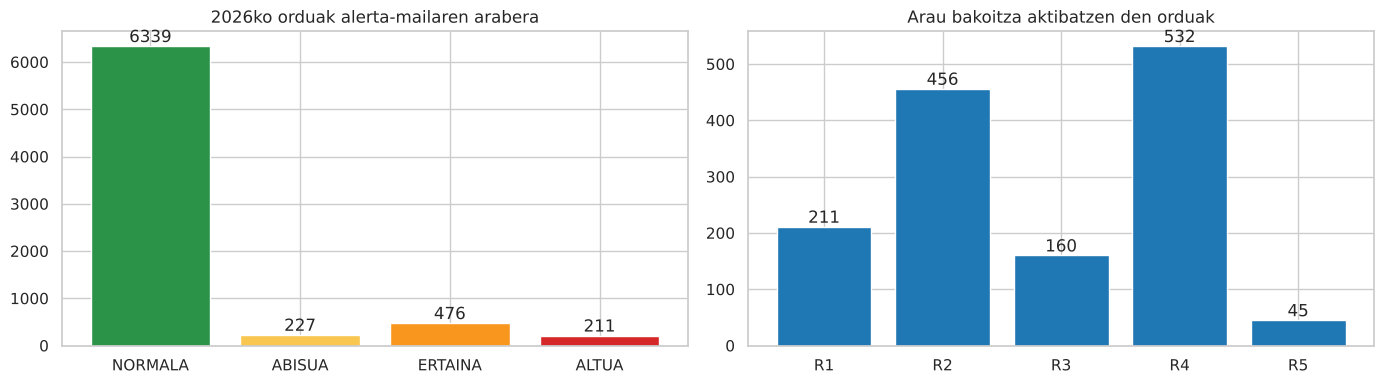

alerta_maila
NORMALA    87.4 %
ABISUA      3.1 %
ERTAINA     6.6 %
ALTUA       2.9 %
Name: count, dtype: str


In [6]:
# Maila bakoitzeko zenbat ordu dauden eta arau bakoitza zenbat aldiz aktibatzen den
mailak = emaitzak["alerta_maila"].value_counts().reindex(["NORMALA", "ABISUA", "ERTAINA", "ALTUA"]).fillna(0).astype(int)
arauak = {araua["id"]: emaitzak["arauak"].str.contains(araua["id"]).sum() for araua in sistema.ARAUAK}

fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
ardatzak[0].bar(mailak.index, mailak.values, color=[MAILA_KOLOREAK[m] for m in mailak.index])
ardatzak[0].set_title("2026ko orduak alerta-mailaren arabera")
for i, v in enumerate(mailak.values):
    ardatzak[0].text(i, v, str(v), ha="center", va="bottom")
ardatzak[1].bar(arauak.keys(), arauak.values(), color="tab:blue")
ardatzak[1].set_title("Arau bakoitza aktibatzen den orduak")
for i, v in enumerate(arauak.values()):
    ardatzak[1].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

print((mailak / len(emaitzak) * 100).round(1).astype(str) + " %")

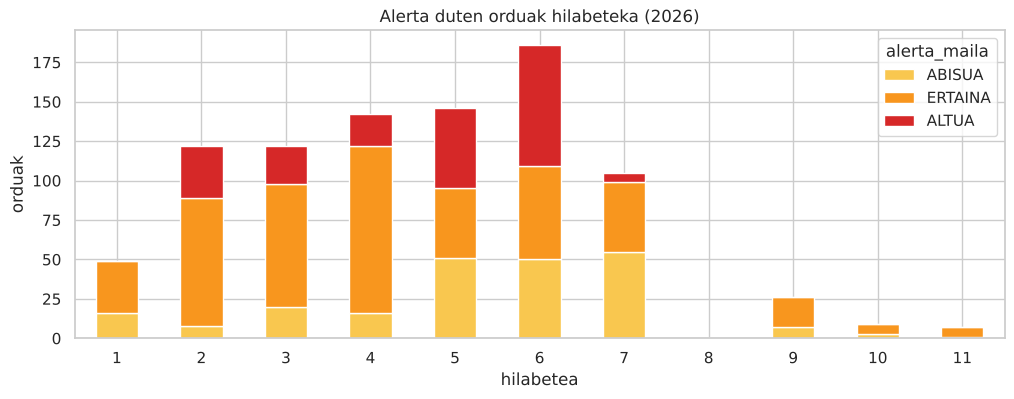

In [ ]:
#alertak hilabeteka
emaitzak["hilabetea"] = emaitzak.index.month
hilabeteka = pd.crosstab(emaitzak["hilabetea"], emaitzak["alerta_maila"])
hilabeteka = hilabeteka[[m for m in ["ABISUA", "ERTAINA", "ALTUA"] if m in hilabeteka.columns]]
hilabeteka.plot(kind="bar", stacked=True, figsize=(12, 4), rot=0, color=[MAILA_KOLOREAK[m] for m in hilabeteka.columns])
plt.title("Alerta duten orduak hilabeteka (2026)")
plt.ylabel("orduak")
plt.show()

### Alertek asmatzen dute?

Arau bakoitza hurrengo orduan benetan gertatu zenarekin alderatzen dugu: partikulen arauak (R1, R2, R4) kalitatea Erregularra edo Txarra izan zen ala ez; R3, NO2ak 40 gainditu zuen; eta R5, NO2ak 30 gainditu zuen.

In [8]:
benetan_txarra = emaitzak["ICA_benetako_hurrengoa"] == "Txarra"
benetan_txarra_edo_erregularra = emaitzak["ICA_benetako_hurrengoa"].isin(["Erregularra", "Txarra"])
benetako_no2 = emaitzak["NO2_benetako_hurrengoa"].astype(float)

iragartzen_duena = {
    "R1": ("kalitate Erregularra edo Txarra", benetan_txarra_edo_erregularra),
    "R2": ("kalitate Erregularra edo Txarra", benetan_txarra_edo_erregularra),
    "R3": ("NO2 > 40 µg/m³", benetako_no2 > 40),
    "R4": ("kalitate Erregularra edo Txarra", benetan_txarra_edo_erregularra),
    "R5": ("NO2 > 30 µg/m³", benetako_no2 > 30),
}

errenkadak = []
for araua in sistema.ARAUAK:
    aktibatua = emaitzak["arauak"].str.contains(araua["id"])
    testua, gertatzen_da = iragartzen_duena[araua["id"]]
    errenkadak.append([araua["id"], araua["maila"], araua["mezua"], aktibatua.sum(), testua,
                       round(100 * (aktibatua & gertatzen_da).sum() / aktibatua.sum(), 1)])

pd.DataFrame(errenkadak, columns=["araua", "maila", "mezua", "aktibatutako orduak", "iragartzen duena", "% asmatzeak"])

,araua,maila,mezua,aktibatutako orduak,iragartzen duena,% asmatzeak
0,R1,ALTUA,Airearen kalitate TXARRA iragarrita,211,kalitate Erregularra edo Txarra,96.2
1,R2,ERTAINA,Partikula altuak eta sakabanatzeko haize gutxi,456,kalitate Erregularra edo Txarra,89.3
2,R3,ERTAINA,NO2 altua iragarrita haize-baretarekin,160,NO2 > 40 µg/m³,80.0
3,R4,ABISUA,Partikula-episodioa martxan,532,kalitate Erregularra edo Txarra,92.3
4,R5,ABISUA,Alderantzizko termiko posiblea puntako orduan,45,NO2 > 30 µg/m³,77.8


In [9]:
# Benetan txarrak izan ziren orduetatik zenbatek izan zuten abisua
partikulak = emaitzak["arauak"].str.contains("R1|R2|R4")
print("ALTUA alerta izan zuten Txarra orduak:", (benetan_txarra & (emaitzak["alerta_maila"] == "ALTUA")).sum(), "/", benetan_txarra.sum())
print("Partikula-alertaren bat (R1, R2 edo R4) izan zuten ordu Erregular edo Txarrak:",
      (benetan_txarra_edo_erregularra & partikulak).sum(), "/", benetan_txarra_edo_erregularra.sum(),
      "(", round(100 * (benetan_txarra_edo_erregularra & partikulak).sum() / benetan_txarra_edo_erregularra.sum(), 1), "% )")
print("R3k abisatutako NO2 > 40 orduak:", ((benetako_no2 > 40) & emaitzak["arauak"].str.contains("R3")).sum(),
      "/", (benetako_no2 > 40).sum())

ALTUA alerta izan zuten Txarra orduak: 128 / 128
Partikula-alertaren bat (R1, R2 edo R4) izan zuten ordu Erregular edo Txarrak: 684 / 781 ( 87.6 % )
R3k abisatutako NO2 > 40 orduak: 128 / 514


In [10]:
# R1 erabaki-zuhaitza bakarrik erabiltzearekin alderatuta
eredua_bakarrik = emaitzak["ICA_iragarria"] == "Txarra"
altua = emaitzak["alerta_maila"] == "ALTUA"
pd.DataFrame({
    "ALTUA alerta duten orduak": [eredua_bakarrik.sum(), altua.sum()],
    "detektatutako Txarra orduak (%)": [100 * (eredua_bakarrik & benetan_txarra).sum() / benetan_txarra.sum(),
                                        100 * (altua & benetan_txarra).sum() / benetan_txarra.sum()],
    "ALTUA alertak ordu Erregular edo Txarretan (%)": [100 * (eredua_bakarrik & benetan_txarra_edo_erregularra).sum() / eredua_bakarrik.sum(),
                                                       100 * (altua & benetan_txarra_edo_erregularra).sum() / altua.sum()],
}, index=["Zuhaitza bakarrik (iragarritako ICA = Txarra)", "Sistema adituna (R1)"]).round(1)

,ALTUA alerta duten orduak,detektatutako Txarra orduak (%),ALTUA alertak ordu Erregular edo Txarretan (%)
Zuhaitza bakarrik (iragarritako ICA = Txarra),211,100.0,96.2
Sistema adituna (R1),211,100.0,96.2


In [11]:
# Alerta-maila hurrengo orduko benetako kalitatearen aldean
pd.crosstab(emaitzak["ICA_benetako_hurrengoa"], emaitzak["alerta_maila"]).reindex(
    index=["Oso ona", "Ona", "Erregularra", "Txarra"], columns=["NORMALA", "ABISUA", "ERTAINA", "ALTUA"]).fillna(0).astype(int)

alerta_maila,NORMALA,ABISUA,ERTAINA,ALTUA
ICA_benetako_hurrengoa,,,,
Oso ona,3627,15,15,2
Ona,2617,38,152,6
Erregularra,95,174,309,75
Txarra,0,0,0,128


- 2026ko 128 ordu "Txarra" guztiek izan zuten ALTUA alerta, eta ALTUA alerten % 96 ordu Erregular edo Txarretan izan ziren. Alarma faltsu gutxi.
- Ordu Erregular eta Txarren % 88k partikula-alertaren bat izan zuten (R1, R2 edo R4). 95 ordu Erregular NORMALA mailan geratu ziren.
- R3 (NO2a) da arau ahulena: NO2 > 40 izan zen orduen laurdena bakarrik abisatzen du. MLPak gailurrak gutxiesten dituenez, atalasera gutxitan iristen da.
- R1ek zuhaitzaren iragarpen bera ematen du; beste arauek testuingurua eta gomendioak gehitzen dituzte.

## 3. 2026ko episodio baten adibidea

Episodioa 2026-05-28 inguruan


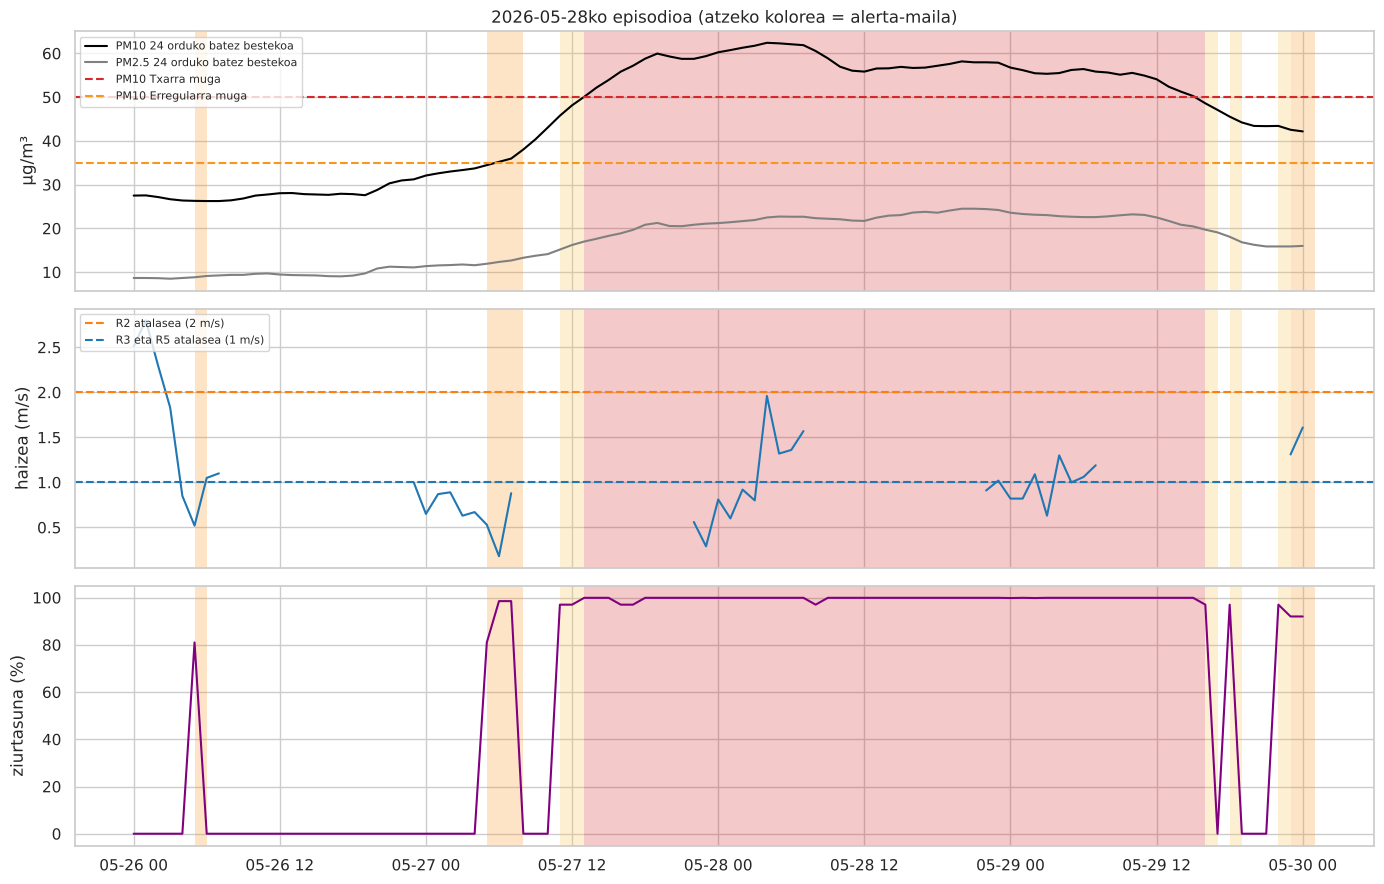

In [12]:
# 2026ko ALTUA alerta ordu gehien dituen eguna bilatzen dugu
eguna = emaitzak[emaitzak["alerta_maila"] == "ALTUA"].index.normalize().value_counts().index[0]
episodioa = emaitzak.loc[eguna - pd.Timedelta(days=2): eguna + pd.Timedelta(days=2)]
print("Episodioa", eguna.date(), "inguruan")

fig, ardatzak = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
ardatzak[0].plot(episodioa.index, episodioa["PM10_batez_24h"], label="PM10 24 orduko batez bestekoa", color="black")
ardatzak[0].plot(episodioa.index, episodioa["PM25_batez_24h"], label="PM2.5 24 orduko batez bestekoa", color="gray")
ardatzak[0].axhline(50, color="#d62828", linestyle="--", label="PM10 Txarra muga")
ardatzak[0].axhline(35, color="#f8961e", linestyle="--", label="PM10 Erregularra muga")
ardatzak[0].set_ylabel("µg/m³")
ardatzak[0].legend(loc="upper left", fontsize=8)
ardatzak[1].plot(episodioa.index, episodioa["haize_abiadura"], color="tab:blue")
ardatzak[1].axhline(2.0, color="tab:orange", linestyle="--", label="R2 atalasea (2 m/s)")
ardatzak[1].axhline(1.0, color="tab:blue", linestyle="--", label="R3 eta R5 atalasea (1 m/s)")
ardatzak[1].set_ylabel("haizea (m/s)")
ardatzak[1].legend(loc="upper left", fontsize=8)
ardatzak[2].plot(episodioa.index, episodioa["ziurtasuna"], color="purple")
ardatzak[2].set_ylabel("ziurtasuna (%)")
for ardatza in ardatzak:
    for ordua, maila in episodioa["alerta_maila"].items():
        if maila != "NORMALA":
            ardatza.axvspan(ordua, ordua + pd.Timedelta(hours=1), color=MAILA_KOLOREAK[maila], alpha=0.25, linewidth=0)
ardatzak[0].set_title(str(eguna.date()) + "ko episodioa (atzeko kolorea = alerta-maila)")
plt.tight_layout()
plt.show()

In [13]:
# Episodioko ALTUA alerta duten lehen orduen azalpena
alertadunak = episodioa[episodioa["alerta_maila"] == "ALTUA"].head(6)
errenkadak_dataka = {e["data"]: e for e in datuak}
for ordua, e in alertadunak.iterrows():
    errenkada = errenkadak_dataka[ordua.strftime("%Y-%m-%d %H:%M")]
    x = sistema.aurreprozesatu(errenkada, sis)
    print(ordua, "| maila", e["alerta_maila"], "| arauak", e["arauak"], "| hurrengo orduko benetako ICA:", e["ICA_benetako_hurrengoa"])
    print("    Zergatik iragartzen du zuhaitzak '" + e["ICA_iragarria"] + "':", sistema.zuhaitzaren_araua(x, sis))

2026-05-27 13:00:00 | maila ALTUA | arauak R1 R4 | hurrengo orduko benetako ICA: Txarra
    Zergatik iragartzen du zuhaitzak 'Txarra': PM10_batez_24h > 20.9 ETA PM10_batez_24h > 35.8 ETA PM10_batez_24h > 49.1 ETA PM10_batez_24h <= 51.8
2026-05-27 14:00:00 | maila ALTUA | arauak R1 R4 | hurrengo orduko benetako ICA: Txarra
    Zergatik iragartzen du zuhaitzak 'Txarra': PM10_batez_24h > 20.9 ETA PM10_batez_24h > 35.8 ETA PM10_batez_24h > 49.1 ETA PM10_batez_24h > 51.8
2026-05-27 15:00:00 | maila ALTUA | arauak R1 R4 | hurrengo orduko benetako ICA: Txarra
    Zergatik iragartzen du zuhaitzak 'Txarra': PM10_batez_24h > 20.9 ETA PM10_batez_24h > 35.8 ETA PM10_batez_24h > 49.1 ETA PM10_batez_24h > 51.8
2026-05-27 16:00:00 | maila ALTUA | arauak R1 | hurrengo orduko benetako ICA: Txarra
    Zergatik iragartzen du zuhaitzak 'Txarra': PM10_batez_24h > 20.9 ETA PM10_batez_24h > 35.8 ETA PM10_batez_24h > 49.1 ETA PM10_batez_24h > 51.8
2026-05-27 17:00:00 | maila ALTUA | arauak R1 | hurrengo orduk

## 4. Ziurtasun-faktoreak

Arau batek ez du beti asmatzen. Apunteetako MYCIN sistemak bezala, arau bakoitzari ziurtasun-faktore bat (ZF) ematen diogu, 0tik 1era: araua betetzen denean ondorioa egia izateko konfiantza.

Gure ondorioa da "hurrengo orduan kutsadura-arazoa egongo da" (ICA Erregularra edo Txarra, edo NO2 > 40). Arau bakoitzaren ZF da 2023-2025ean araua bete zen orduetatik zenbatetan izan zen egia. Proba-urtea (2026) ez dugu erabiltzen ZFak kalkulatzeko.

Arau bat baino gehiago betetzen direnean, MYCINen formularekin konbinatzen dira:

ZF = ZF1 + ZF2 · (1 − ZF1)

Arau bakoitzak konfiantza gehitzen du, baina emaitza ez da inoiz 1etik pasatzen.

In [ ]:
# ZFak entrenamenduko datuekin kalkulatu
entrenamendua = pd.read_csv("../data/prozesatuak/barakaldo_entrenamendua.csv")
entr_emaitzak = pd.DataFrame([sistema.ordua_prozesatu(errenkada, sis)[0] for errenkada in entrenamendua.to_dict("records")])

def arazoa(df):
    # Ondorioa: hurrengo orduan ICA Erregularra edo Txarra, edo NO2 > 40
    return df["ICA_benetako_hurrengoa"].isin(["Erregularra", "Txarra"]) | (df["NO2_benetako_hurrengoa"] > 40)

entr_arazoa = arazoa(entr_emaitzak)
taula = []
for araua in sistema.ARAUAK:
    bete = entr_emaitzak["arauak"].str.split().apply(lambda idak: araua["id"] in idak)
    taula.append([araua["id"], araua["maila"], bete.sum(), round(entr_arazoa[bete].mean(), 2), araua["zf"]])
pd.DataFrame(taula, columns=["araua", "maila", "bete den orduak (2023-2025)", "ZF kalkulatua", "ZF sistema.py-n"])

,araua,maila,bete den orduak (2023-2025),ZF kalkulatua,ZF sistema.py-n
0,R1,ALTUA,443,0.97,0.97
1,R2,ERTAINA,1643,0.92,0.92
2,R3,ERTAINA,1043,0.81,0.81
3,R4,ABISUA,1056,0.97,0.97
4,R5,ABISUA,468,0.48,0.48


In [15]:
# Konbinazioaren adibidea
r2 = sistema.ARAUAK[1]["zf"]
r4 = sistema.ARAUAK[3]["zf"]
print("R2 bakarrik:", r2)
print("R4 bakarrik:", r4)
print("R2 eta R4 batera:", round(r2 + r4 * (1 - r2), 3))

R2 bakarrik: 0.92
R4 bakarrik: 0.97
R2 eta R4 batera: 0.998


In [ ]:
# Egiaztapena 2026an
emaitzak["arazoa"] = arazoa(emaitzak)
tarteak = pd.cut(emaitzak["ziurtasuna"], bins=[-1, 0, 80, 95, 100], labels=["0 (alertarik ez)", "1-80", "80-95", "95-100"])
emaitzak.groupby(tarteak, observed=True)["arazoa"].agg(orduak="count", arazoa_benetan=lambda a: round(a.mean() * 100, 1))

,orduak,arazoa_benetan
ziurtasuna,,
0 (alertarik ez),6339,5.9
1-80,29,0.0
80-95,287,82.2
95-100,598,92.5


- Arau gehienen ZFa altua da (0,81-0,97). R5ena 0,48 da: goiz hotz eta bareetan NO2a igotzen da, baina askotan ez da 40ra iristen.
- 2026an ZFak ondo funtzionatzen dute: ziurtasuna % 95etik gorakoa denean, orduen % 92,5ean egon zen benetan arazoa; % 80-95 denean, % 82an; eta alertarik ez dagoenean, % 6an bakarrik.
- 1-80 tartea R5 bakarrik betetzen den orduak dira (29), eta 2026an ordu horietako batean ere ez zen arazorik egon. Komeni litzateke R5 berrikustea edo kentzea.

## 5. Ondorioak

- Bost arauko sistema adituak 2026ko ordu "Txarra" guztiak detektatzen ditu, eta alerta bakoitzak zergatia, gomendioa eta ziurtasuna ematen ditu.
- Partikulen arauak (R1, R2, R4) ondo dabiltza. NO2arena (R3) hobetu beharko litzateke, MLPak gailurrak gutxiesten dituelako, eta R5ek ziurtasun txikia du.
- Ziurtasun-faktoreek alerta bakoitza zenbateraino den fidagarria esaten dute, eta aginte-panelean ehuneko gisa erakusten dira.